# Activity 1 — Python basics: GDP, oil and night-time lights in Trinidad and Tobago

This first activity uses basic Python to load and look at data. We will:

- Load three datasets: **real GDP** (quarterly), the **Brent crude oil price** (daily) and
  **night-time lights** over Trinidad and Tobago (daily, from NASA's Black Marble satellite product)
- Clean what needs cleaning
- Resample the three series to a common frequency and merge them
- Compute descriptive statistics and growth rates
- Plot the data

The data are in the `data/` folder, one level above this notebook (`../data/`).

Cells marked `<YOUR CODE HERE: ...>` are for you to complete. The solution is in
`sols/act1_python_basics.ipynb`.

In [1]:
# Verify this line runs correctly.
# Otherwise, go back to install/act0_env_check.ipynb

import pandas as pd  # import the pandas library and give it the alias "pd"

## 1. Load the GDP data

`gdp.csv` holds Trinidad and Tobago's **real GDP** (TT$ millions, constant prices), published
quarterly by the Central Statistical Office. It is the series we will nowcast for the rest
of the workshop.

In [2]:
df_gdp = pd.read_csv('../data/gdp.csv',      # path is relative to this notebook
                     index_col='date',       # use the 'date' column as the row index instead of 0, 1, 2, ...
                     parse_dates=True)       # convert the index to datetime objects automatically
df_gdp = df_gdp.dropna()                     # drop missing values

# Observe the data
df_gdp.tail(5)                               # show the last 5 rows of the DataFrame

,rgdp
date,
2025-03-01,35286.342226
2025-06-01,36811.895707
2025-09-01,37594.126550
2025-12-01,37703.621567
2026-03-01,34645.058555


It has a single series, `rgdp`. Give it a shorter name and select it explicitly — the
double brackets keep the result a **DataFrame** rather than a Series.

In [3]:
df_gdp = df_gdp.rename(columns={'rgdp': 'gdp'})   # rename the column
df_gdp = df_gdp[['gdp']]
df_gdp.head(5)                                     # show the first 5 rows

,gdp
date,
2012-03-01,41771.735003
2012-06-01,42031.523106
2012-09-01,42480.082117
2012-12-01,41712.972524
2013-03-01,41987.378641


## 2. Load the oil price

**COMPLETE.** `eia_brent.csv` is the daily **Brent crude** spot price (US$ per barrel) from the
US Energy Information Administration. Energy is roughly a third of Trinidad and Tobago's
economy, so oil and gas prices are an obvious candidate predictor.

In [4]:
# YOUR CODE HERE: call pd.read_csv(...) with the Brent file path, index_col='date', parse_dates=True
df_oil = pd.read_csv('../data/eia_brent.csv', index_col='date', parse_dates=True)

df_oil.tail(5)  # show the last 5 rows to verify the data loaded correctly

,brent price
date,
2026-10-08,130.18
2026-10-09,130.03
2026-10-12,129.95
2026-10-13,125.78
2026-10-14,126.55


The column name has a space in it (`brent price`), which makes it awkward to type.
Rename it.

In [5]:
df_oil = df_oil.rename(columns={'brent price': 'brent'})
df_oil.tail(3)

,brent
date,
2026-10-12,129.95
2026-10-13,125.78
2026-10-14,126.55


## 3. Load the night-time lights

**COMPLETE.** Open `ntl_shape.csv`: one row per **day**, measured over the whole country.

| column | meaning |
|---|---|
| `shape_mean` | average radiance over Trinidad and Tobago (nW/cm²/sr) |
| `shape_sum` | total radiance (the mean times the number of pixels) |

We will build this file ourselves from the satellite tiles in Activity 3.

In [6]:
df_ntl = pd.read_csv('../data/ntl_shape.csv', index_col='date', parse_dates=True)

df_ntl.head(10)  # .head shows the first rows, .tail the last

,shape_mean,shape_sum
date,,
2012-01-19,8.291780,203405.655986
2012-01-20,9.938151,243792.788077
2012-01-21,7.931987,194579.568474
2012-01-22,7.554746,185325.471618
2012-01-23,6.426484,157648.071626
2012-01-24,7.511431,184262.917716
2012-01-25,8.642458,212008.126163
2012-01-26,10.322367,253217.973959
2012-01-27,7.197056,176550.983747


Keep only `shape_mean`.

In [7]:
# Double brackets [[ ]] select a subset of columns and return a DataFrame (single brackets return a Series)
df_ntl = df_ntl[['shape_mean']]
df_ntl.head(5)

,shape_mean
date,
2012-01-19,8.291780
2012-01-20,9.938151
2012-01-21,7.931987
2012-01-22,7.554746
2012-01-23,6.426484


Let's look at it.

<Axes: xlabel='date'>

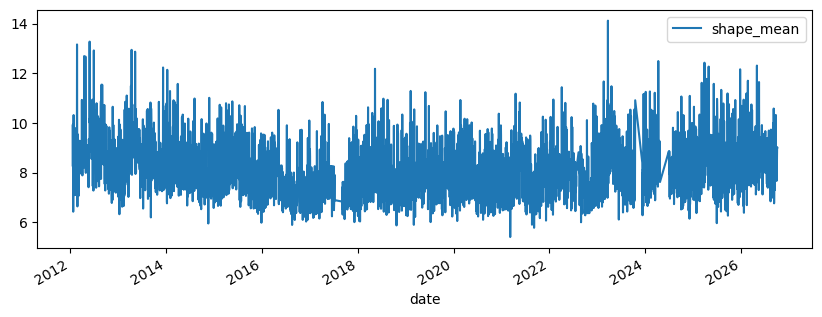

In [8]:
df_ntl.plot(figsize=(10, 3.5))

Daily satellite data are **noisy and gappy**. A day is missing when clouds cover the island,
when the satellite's quality flags reject the pixels, or when there was no overpass. How many
days are missing?

In [9]:
all_days = pd.date_range(df_ntl.index.min(), df_ntl.index.max(), freq='D')
missing  = len(all_days) - df_ntl['shape_mean'].notna().sum()
print(f"{missing:,} of {len(all_days):,} days have no value ({missing / len(all_days):.0%})")

301 of 5,373 days have no value (6%)


## 4. One frequency for all three series

The three series are on **different frequencies**: GDP is quarterly, oil and lights are daily.
Series cannot be merged until they share a frequency, and the slowest one — GDP — decides it.

**COMPLETE**: resample the lights to quarterly averages. `QS` stands for *Quarter Start*,
`QE` for *Quarter End*. Averaging over a quarter also washes out most of the daily noise.

In [10]:
# Pass a frequency string inside resample(), e.g. resample('QS') for Quarter Start.
# .mean() then averages all daily values that fall within each quarter
df_ntl = df_ntl.resample('QS').mean()
df_ntl.tail(10)

,shape_mean
date,
2024-07-01,8.247644
2024-10-01,8.094823
2025-01-01,8.459727
2025-04-01,8.830901
2025-07-01,8.155445
2025-10-01,8.610360
2026-01-01,8.701489
2026-04-01,8.896684
2026-07-01,8.489872


The last quarter is incomplete (and may be empty). `dropna(how='all')` removes rows where
every column is missing.

In [11]:
# how='all' means: only drop a row if ALL its columns are NaN
# axis=0 means operate on rows (axis=1 would operate on columns)
df_ntl = df_ntl.dropna(how='all', axis=0)
df_ntl.tail(5)

,shape_mean
date,
2025-10-01,8.610360
2026-01-01,8.701489
2026-04-01,8.896684
2026-07-01,8.489872
2026-10-01,8.650044


Descriptive statistics:

In [12]:
df_ntl.describe()  # count, mean, std, min, quartiles, and max for each numeric column

,shape_mean
count,60.000000
mean,8.172086
std,0.470579
min,7.158935
25%,7.825121
50%,8.127306
75%,8.480385
max,9.320109


**COMPLETE**: plot the quarterly series. Compare it with the daily plot above.

<Axes: xlabel='date'>

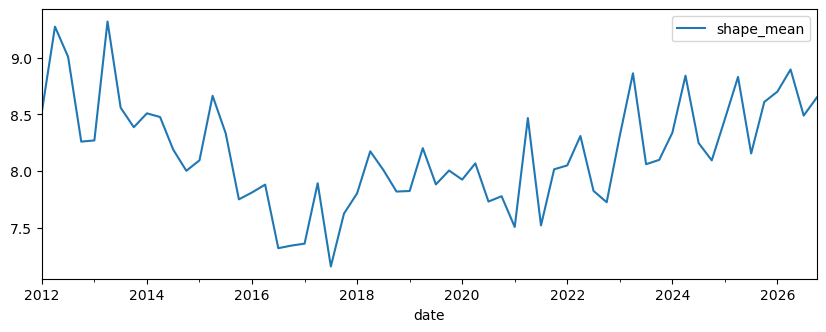

In [13]:
df_ntl.plot(figsize=(10, 3.5))

# 5. Merge the data

We have three series:

(<Axes: xlabel='date'>, <Axes: xlabel='date'>, <Axes: xlabel='date'>)

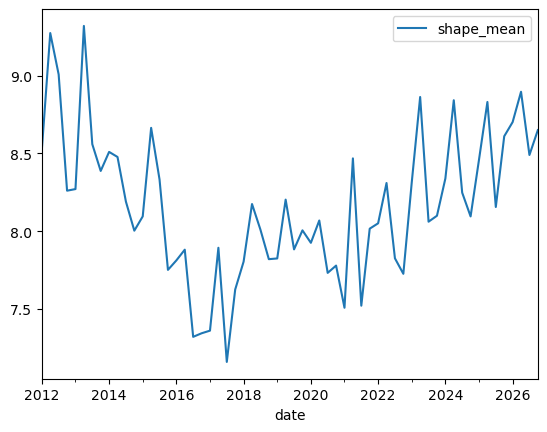

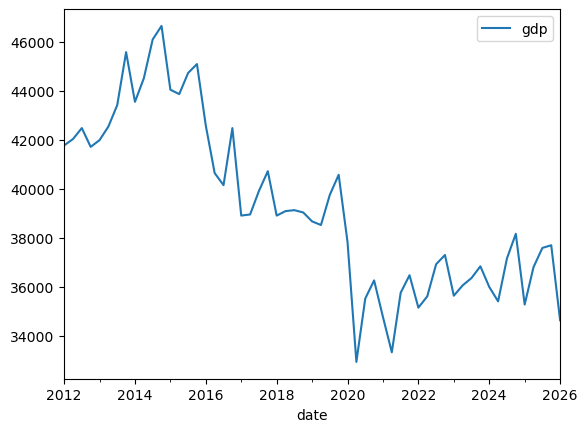

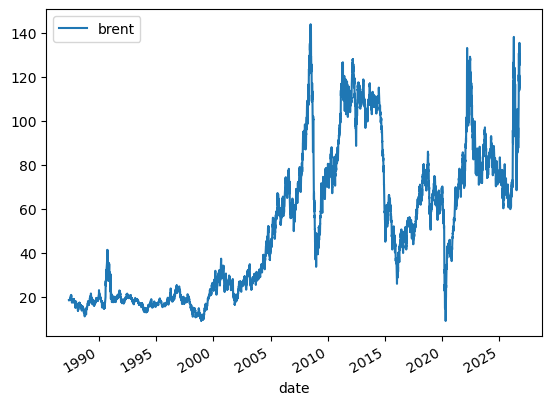

In [14]:
# Calling .plot() on each DataFrame draws a separate chart for each series
df_ntl.plot(), df_gdp.plot(), df_oil.plot()

**COMPLETE**: resample the oil price into quarters (Quarter Start), averaging.

In [15]:
df_oil = df_oil.resample('QS').mean()

df_oil.tail(5)

,brent
date,
2025-10-01,63.654219
2026-01-01,80.719841
2026-04-01,102.625902
2026-07-01,96.299538
2026-10-01,126.977000


Now merge, but...

In [16]:
# .merge() joins two DataFrames, like a SQL JOIN.
# left_index=True, right_index=True: use the row index (date) as the join key on both sides
df_merge = df_ntl.merge(df_gdp, left_index=True, right_index=True)
df_merge = df_merge.merge(df_oil, left_index=True, right_index=True)   # chain a second merge
df_merge

,shape_mean,gdp,brent
date,,,


It is empty. This is a very common problem: the date indexes do not align. Look at the three:

In [17]:
df_gdp.tail(3)

,gdp
date,
2025-09-01,37594.126550
2025-12-01,37703.621567
2026-03-01,34645.058555


In [18]:
df_oil.tail(3)

,brent
date,
2026-04-01,102.625902
2026-07-01,96.299538
2026-10-01,126.977000


In [19]:
df_ntl.tail(3)

,shape_mean
date,
2026-04-01,8.896684
2026-07-01,8.489872
2026-10-01,8.650044


GDP is stamped on the **first day of the last month** of each quarter (1 March, 1 June, ...).
That is the convention in every pipeline of this project: a quarter is dated by the month in
which it ends. `resample('QS')` gave the other two the **start** of the quarter (1 January,
1 April, ...).

Several fixes exist. **COMPLETE** the simplest one: resample GDP to `QS` as well.

In [20]:
df_gdp = df_gdp.resample('QS').mean()
df_gdp.tail(3)

,gdp
date,
2025-07-01,37594.126550
2025-10-01,37703.621567
2026-01-01,34645.058555


In [21]:
# Now that the date indexes match, the merge produces rows
df_merge = df_ntl.merge(df_gdp, left_index=True, right_index=True)
df_merge = df_merge.merge(df_oil, left_index=True, right_index=True)
df_merge

,shape_mean,gdp,brent
date,,,
2012-01-01,8.524389,41771.735003,118.710645
2012-04-01,9.274199,42031.523106,107.749833
2012-07-01,9.007862,42480.082117,109.628413
2012-10-01,8.260337,41712.972524,110.147813
2013-01-01,8.270714,41987.378641,112.443333
2013-04-01,9.320109,42541.691348,102.564688
2013-07-01,8.559512,43416.386363,110.228594
2013-10-01,8.387327,45576.128471,109.226406
2014-01-01,8.509783,43549.323681,108.141935


Plot:

<Axes: xlabel='date'>

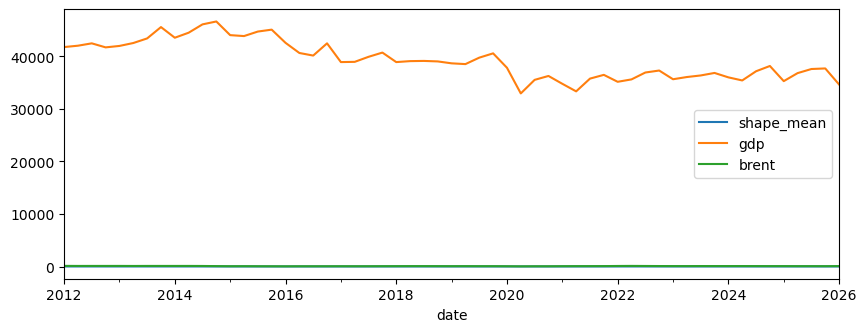

In [22]:
df_merge.plot(figsize=(10, 3.5))

GDP is in the tens of thousands, the other two below 150, so the chart is useless. Make the
comparison meaningful by turning each series into a **quarter-on-quarter rate of change**.

In [23]:
# (current - previous) / previous. fill_method=None: do not fill gaps before computing
df_change = df_merge.pct_change(fill_method=None)
df_change.head(5)   # the first row is NaN: there is no previous quarter

,shape_mean,gdp,brent
date,,,
2012-01-01,NaN,NaN,NaN
2012-04-01,0.087961,0.006219,-0.092332
2012-07-01,-0.028718,0.010672,0.017435
2012-10-01,-0.082986,-0.018058,0.004738
2013-01-01,0.001256,0.006578,0.020840


<Axes: xlabel='date'>

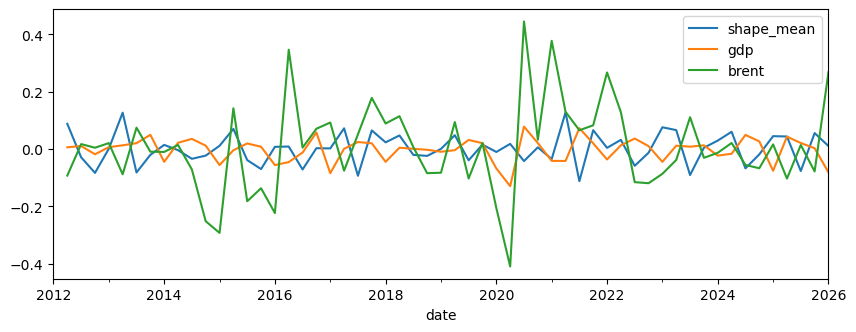

In [24]:
df_change.plot(figsize=(10, 3.5))

# 6. Which series moves with GDP?

**COMPLETE**: compute the correlation matrix of the quarterly growth rates with `.corr()`.

In [25]:
df_change.corr()

,shape_mean,gdp,brent
shape_mean,1.000000,-0.295529,-0.006125
gdp,-0.295529,1.000000,0.128356
brent,-0.006125,0.128356,1.000000


GDP here is **not seasonally adjusted**, so quarter-on-quarter changes mix the business cycle with
the season. A quick fix is the **year-on-year** change: compare each quarter with the same
quarter a year earlier.

**COMPLETE**: `pct_change(4)` compares a quarter with the one four periods earlier.

In [26]:
df_yoy = df_merge.pct_change(4, fill_method=None)
df_yoy.corr()

,shape_mean,gdp,brent
shape_mean,1.000000,0.255670,0.253846
gdp,0.255670,1.000000,0.213633
brent,0.253846,0.213633,1.000000


<Axes: title={'center': 'Year-on-year change'}, xlabel='date'>

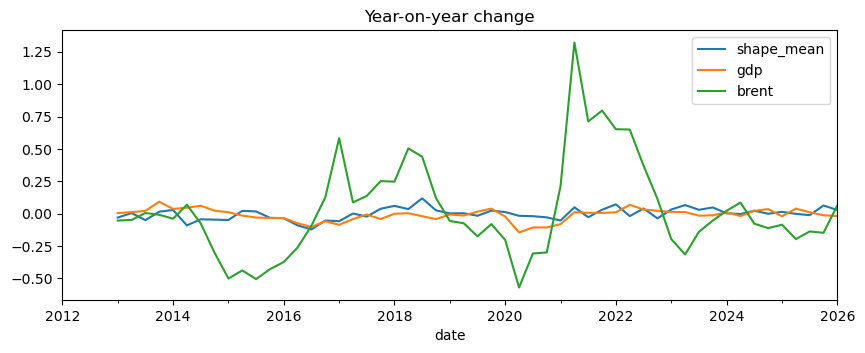

In [27]:
df_yoy.plot(figsize=(10, 3.5), title='Year-on-year change')

### Questions to discuss

1. Which series is more correlated with GDP growth: oil prices or night-time lights?
   Does the answer change between quarter-on-quarter and year-on-year?
2. Trinidad and Tobago exports oil **and gas**. Is the Brent price the right energy price to track?
3. Night-time lights over the whole country mix towns, industry and gas flares. In Activity 3 we
   will measure lights **site by site** — refineries, petrochemical plants, ports, malls.